# Lab RNN: Phân loại thể loại nhạc từ xu hướng theo năm (Spotify Global Music 2009–2025)

**Bài toán:** với mỗi thể loại, tính chuỗi giá trị trung bình theo năm của các feature (độ phổ biến bài hát, thời lượng, tỷ lệ explicit).
RNN nhận một chuỗi như vậy và dự đoán chuỗi đó thuộc thể loại nào.

**Điều chỉnh so với plan gốc (có chủ đích):**
- Dataset không có `energy`/`valence` → dùng `track_popularity`, `duration_min`, `explicit_rate`.
- Mỗi bài hát có thể thuộc nhiều thể loại (`artist_genres` là list) → explode: một bài xuất hiện ở mỗi thể loại của nghệ sĩ. Khoảng 51% bài có list rỗng và bị loại.
- Chỉ có N thể loại ⇒ N chuỗi, quá ít để train. Cách xử lý: (1) chia **theo nghệ sĩ** thành train/val/test (không nghệ sĩ nào xuất hiện ở 2 tập), (2) trong mỗi tập, tạo nhiều chuỗi bằng cách lấy **mẫu con ngẫu nhiên** các bài hát rồi tính trung bình theo năm, (3) cắt **sliding window**.

In [1]:
import ast
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("data/raw/track_data_final.csv")
YEAR_MIN, YEAR_MAX = 2009, 2025
TOP_N = 6
FEATURES = ["track_popularity", "duration_min", "explicit_rate"]

## 1. Khám phá dữ liệu (EDA)

In [2]:
df = pd.read_csv(DATA_PATH)
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 8778 entries, 0 to 8777
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8778 non-null   str    
 1   track_name          8776 non-null   str    
 2   track_number        8778 non-null   int64  
 3   track_popularity    8778 non-null   int64  
 4   track_duration_ms   8778 non-null   int64  
 5   explicit            8778 non-null   bool   
 6   artist_name         8774 non-null   str    
 7   artist_popularity   8774 non-null   float64
 8   artist_followers    8774 non-null   float64
 9   artist_genres       8774 non-null   str    
 10  album_id            8778 non-null   str    
 11  album_name          8776 non-null   str    
 12  album_release_date  8778 non-null   str    
 13  album_total_tracks  8778 non-null   int64  
 14  album_type          8778 non-null   str    
dtypes: bool(1), float64(2), int64(4), str(8)
memory usage: 968.8 KB


,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album
3,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album
4,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album


In [3]:
df.describe()

,track_number,track_popularity,track_duration_ms,artist_popularity,artist_followers,album_total_tracks
count,8778.000000,8778.000000,8778.000000,8774.000000,8.774000e+03,8778.000000
mean,5.749487,52.232855,210157.791866,69.954981,2.435487e+07,13.779790
std,6.017938,24.075221,63326.841454,19.532783,3.813769e+07,11.797943
min,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000
25%,1.000000,39.000000,173921.250000,60.000000,5.152768e+05,6.000000
50%,4.000000,58.000000,207276.000000,74.000000,6.272266e+06,13.000000
75%,9.000000,71.000000,239693.250000,84.000000,3.055055e+07,17.000000
max,102.000000,100.000000,811077.000000,100.000000,1.455421e+08,181.000000


In [4]:
# Làm sạch & tạo cột dẫn xuất
df["year"] = pd.to_datetime(df["album_release_date"], errors="coerce").dt.year
df["duration_min"] = df["track_duration_ms"] / 60000
df["explicit_rate"] = df["explicit"].astype(int)  # trung bình theo nhóm = tỷ lệ explicit
df["genres"] = df["artist_genres"].fillna("[]").apply(ast.literal_eval)

print("Thiếu giá trị:\n", df[["year", "artist_name", "artist_genres", "track_popularity", "track_duration_ms"]].isna().sum())
print("Bài có duration = 0:", (df["track_duration_ms"] <= 0).sum())
print("Bài có genre rỗng: %.1f%%" % (100 * (df["genres"].str.len() == 0).mean()))
print("Năm: %d – %d" % (df["year"].min(), df["year"].max()))

df = df.dropna(subset=["year", "artist_name"])
df = df[df["track_duration_ms"] > 0]
df["year"] = df["year"].astype(int)

Thiếu giá trị:
 year                 201
artist_name            4
artist_genres          4
track_popularity       0
track_duration_ms      0
dtype: int64
Bài có duration = 0: 2
Bài có genre rỗng: 51.2%
Năm: 1952 – 2025


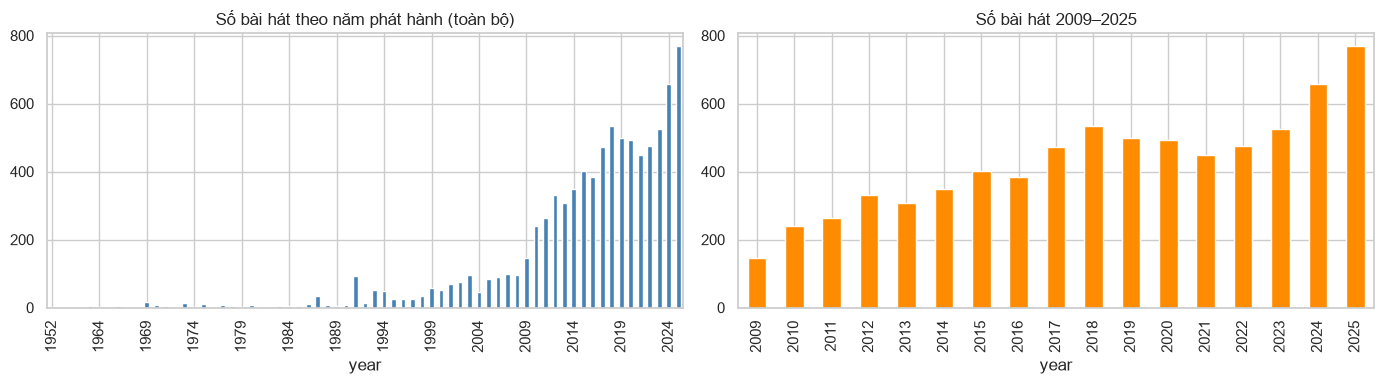

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["year"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Số bài hát theo năm phát hành (toàn bộ)")
ax[0].set_xticks(ax[0].get_xticks()[::5])
tracks_per_year = df[df["year"].between(YEAR_MIN, YEAR_MAX)]["year"].value_counts().sort_index()
tracks_per_year.plot(kind="bar", ax=ax[1], color="darkorange")
ax[1].set_title(f"Số bài hát {YEAR_MIN}–{YEAR_MAX}")
plt.tight_layout(); plt.show()

Số thể loại khác nhau: 372
Top 6 thể loại: ['pop', 'soundtrack', 'rap', 'soft pop', 'country', 'art pop']


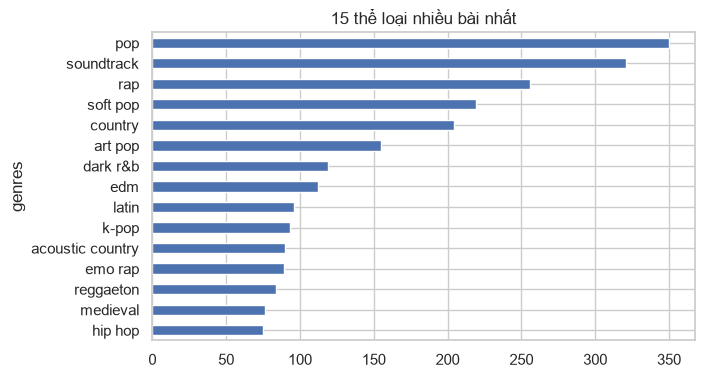

In [6]:
exploded = df[df["year"].between(YEAR_MIN, YEAR_MAX)].explode("genres").dropna(subset=["genres"])
print("Số thể loại khác nhau:", exploded["genres"].nunique())
genre_counts = exploded["genres"].value_counts()
top_genres = genre_counts.head(TOP_N).index.tolist()
print("Top", TOP_N, "thể loại:", top_genres)
genre_counts.head(15).plot(kind="barh", figsize=(7, 4)).invert_yaxis()
plt.title("15 thể loại nhiều bài nhất"); plt.show()

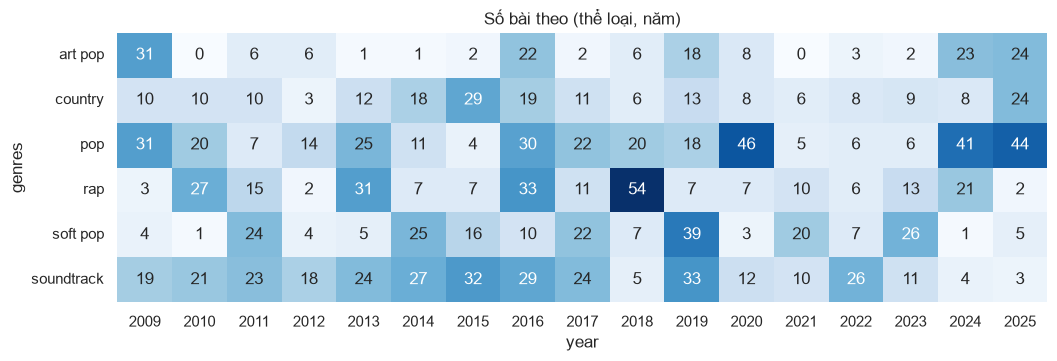

In [7]:
# Độ phủ năm của các thể loại được chọn
data = exploded[exploded["genres"].isin(top_genres)]
coverage = data.pivot_table(index="genres", columns="year", values="track_id", aggfunc="count", fill_value=0)
plt.figure(figsize=(12, 3.5))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Số bài theo (thể loại, năm)"); plt.show()

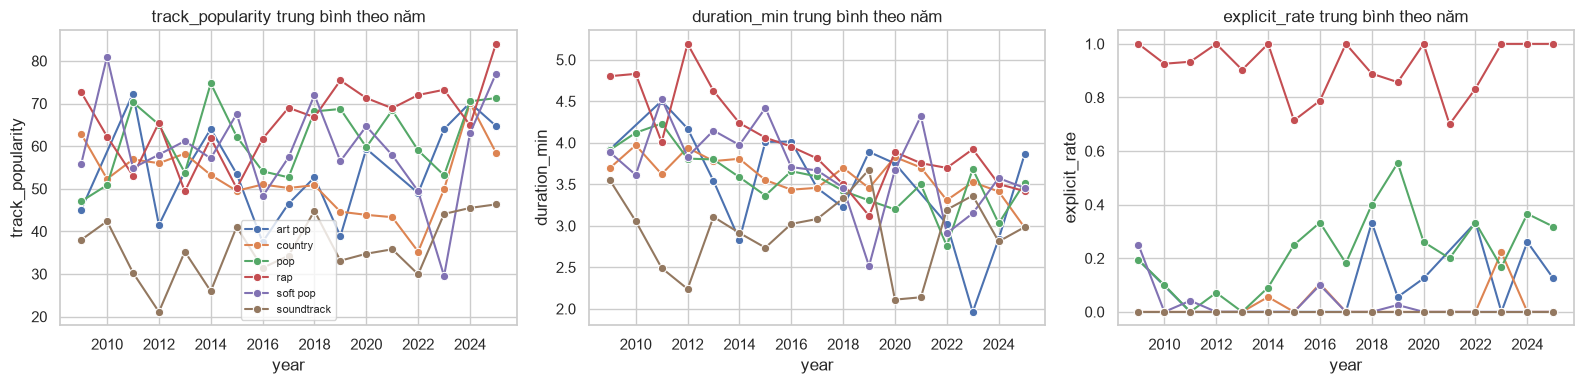

In [8]:
agg = data.groupby(["genres", "year"])[FEATURES].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feat in zip(axes, FEATURES):
    sns.lineplot(data=agg, x="year", y=feat, hue="genres", marker="o", ax=ax)
    ax.set_title(f"{feat} trung bình theo năm")
axes[0].legend(fontsize=8); axes[1].legend().remove(); axes[2].legend().remove()
plt.tight_layout(); plt.show()

## 2. Chia dữ liệu theo nghệ sĩ

Chia **trước** khi tạo chuỗi và chia theo `artist_name`, vì các chuỗi con-mẫu của cùng một tập bài hát sẽ rất giống nhau; nếu chia sau, test sẽ rò rỉ từ train.

In [9]:
YEARS = list(range(YEAR_MIN, YEAR_MAX + 1))
SEQ_LEN = len(YEARS)

MIN_POOL = 15  # số bài tối thiểu mỗi thể loại ở val/test, tránh chuỗi suy biến (vd 1 bài duy nhất)

def split_by_artist(frame, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(frame, groups=frame["artist_name"]))
    return frame.iloc[a], frame.iloc[b]

def split_all(seed):
    rest, test_df = split_by_artist(data, 0.15, seed)
    train_df, val_df = split_by_artist(rest, 0.15 / 0.85, seed)
    return train_df, val_df, test_df

def pools_ok(parts):
    return all(p["genres"].value_counts().reindex(top_genres, fill_value=0).min() >= MIN_POOL for p in parts)

# Chọn seed đầu tiên mà val và test đều có đủ bài cho mọi thể loại
split_seed = next(s for s in range(SEED, SEED + 500) if pools_ok(split_all(s)[1:]))
train_df, val_df, test_df = split_all(split_seed)
print("split_seed =", split_seed)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(part), "dòng;", part["artist_name"].nunique(), "nghệ sĩ")
    print(part["genres"].value_counts().to_dict())
assert not (set(train_df.artist_name) & set(test_df.artist_name))
assert not (set(train_df.artist_name) & set(val_df.artist_name))
assert not (set(val_df.artist_name) & set(test_df.artist_name))

split_seed = 145
train 1003 dòng; 137 nghệ sĩ
{'soundtrack': 241, 'pop': 217, 'rap': 202, 'soft pop': 181, 'country': 137, 'art pop': 25}
val 237 dòng; 30 nghệ sĩ
{'pop': 66, 'soundtrack': 46, 'country': 36, 'rap': 35, 'art pop': 33, 'soft pop': 21}
test 265 dòng; 30 nghệ sĩ
{'art pop': 97, 'pop': 67, 'soundtrack': 34, 'country': 31, 'rap': 19, 'soft pop': 17}


## 3. Dựng sequence

- `make_series`: lấy ngẫu nhiên `frac` số bài của một thể loại (trong một tập), trung bình theo năm, nội suy các năm thiếu → ma trận `(17 năm, 3 feature)`.
- Cắt sliding window độ dài `WINDOW` (stride 1). Nhãn = thể loại gốc.

In [10]:
CLASSES = sorted(top_genres)
CLASS_TO_ID = {g: i for i, g in enumerate(CLASSES)}
WINDOW, FRAC = 8, 0.6
N_REPLICATES = {"train": 100, "val": 25, "test": 25}

def make_series(pool, rng):
    sample = pool.sample(frac=FRAC, random_state=int(rng.integers(1 << 31)))
    by_year = sample.groupby("year")[FEATURES].mean().reindex(YEARS)
    # Nội suy năm thiếu; năm thiếu ở hai đầu được fill bằng giá trị gần nhất
    return by_year.interpolate(limit_direction="both").to_numpy(dtype=np.float32)

def build_split(frame, n_rep, seed):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for genre in CLASSES:
        pool = frame[frame["genres"] == genre]
        for _ in range(n_rep):
            series = make_series(pool, rng)
            if np.isnan(series).any():  # thể loại không có bài nào trong tập này
                continue
            for start in range(SEQ_LEN - WINDOW + 1):
                X.append(series[start:start + WINDOW])
                y.append(CLASS_TO_ID[genre])
    return np.stack(X), np.array(y)

X_train, y_train = build_split(train_df, N_REPLICATES["train"], SEED)
X_val, y_val = build_split(val_df, N_REPLICATES["val"], SEED + 1)
X_test, y_test = build_split(test_df, N_REPLICATES["test"], SEED + 2)
print(X_train.shape, X_val.shape, X_test.shape)
print("Phân bố nhãn train:", np.bincount(y_train), "| test:", np.bincount(y_test))

(6000, 8, 3) (1500, 8, 3) (1500, 8, 3)
Phân bố nhãn train: [1000 1000 1000 1000 1000 1000] | test: [250 250 250 250 250 250]


In [11]:
# Chuẩn hoá: fit trên train, áp dụng cho val/test
scaler = StandardScaler().fit(X_train.reshape(-1, len(FEATURES)))
scale = lambda X: scaler.transform(X.reshape(-1, len(FEATURES))).reshape(X.shape).astype(np.float32)
X_train, X_val, X_test = scale(X_train), scale(X_val), scale(X_test)

def loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_loader, val_loader, test_loader = loader(X_train, y_train, True), loader(X_val, y_val, False), loader(X_test, y_test, False)

## 4. Mô hình: SimpleRNN, LSTM, GRU

Cùng kiến trúc: recurrent layer (hidden 32) → lấy hidden state cuối → Dropout(0.2) → Dense(16, ReLU) → Dense(n_classes).
Softmax được gộp trong `CrossEntropyLoss`.

In [12]:
class SeqClassifier(nn.Module):
    def __init__(self, rnn_type, n_features, n_classes, hidden=32):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[rnn_type](n_features, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, n_classes))

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])

def run_epoch(model, loader_, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader_:
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def fit(rnn_type, epochs=60, patience=8, lr=1e-3):
    torch.manual_seed(SEED)
    model = SeqClassifier(rnn_type, len(FEATURES), len(CLASSES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    best, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        l, a = run_epoch(model, train_loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)
        for k, v in zip(hist, (l, vl, a, va)):
            hist[k].append(v)
        if vl < best - 1e-4:
            best, best_state, wait = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    print(f"{rnn_type}: dừng sau {len(hist['loss'])} epoch, best val_loss={best:.4f}")
    return model, hist

models, histories = {}, {}
for t in ["RNN", "LSTM", "GRU"]:
    models[t], histories[t] = fit(t)

RNN: dừng sau 9 epoch, best val_loss=1.0910


LSTM: dừng sau 10 epoch, best val_loss=1.2353


GRU: dừng sau 9 epoch, best val_loss=1.0818


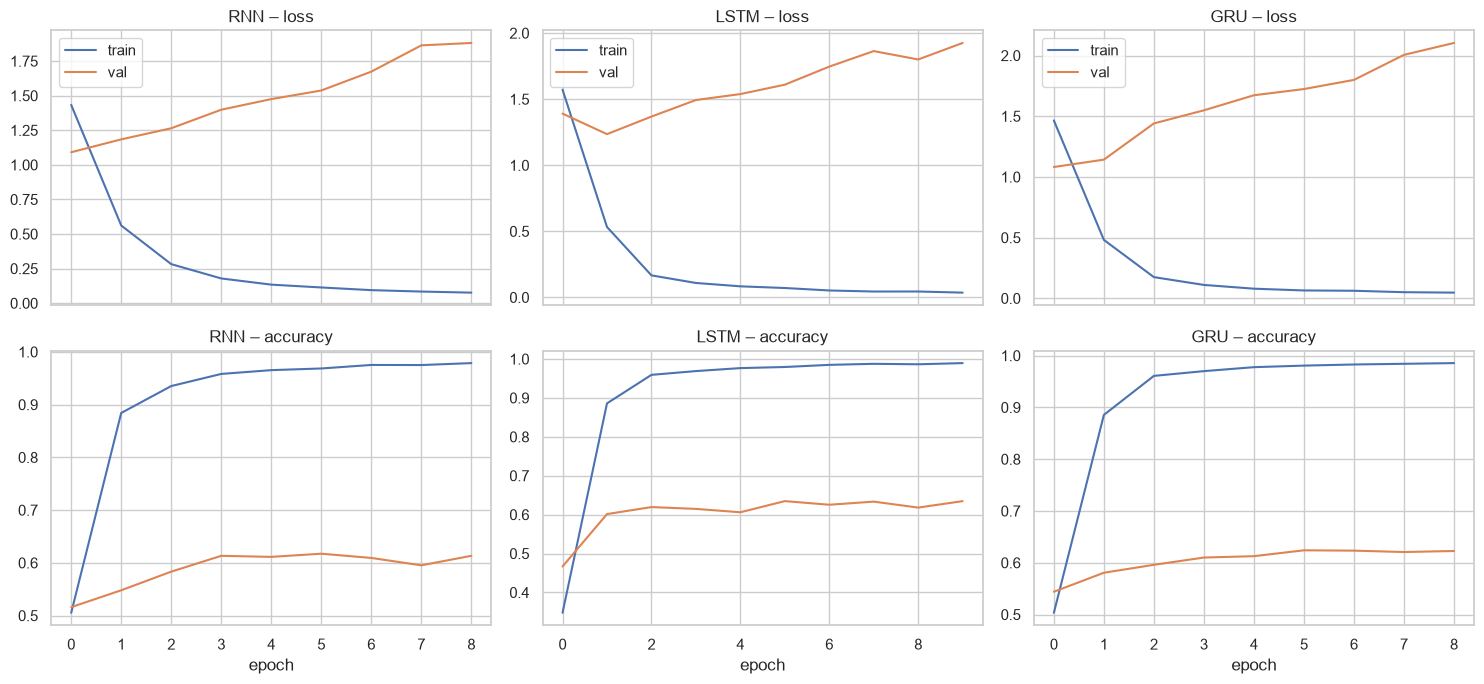

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex="col")
for j, t in enumerate(models):
    h = histories[t]
    axes[0, j].plot(h["loss"], label="train"); axes[0, j].plot(h["val_loss"], label="val")
    axes[0, j].set_title(f"{t} – loss"); axes[0, j].legend()
    axes[1, j].plot(h["acc"], label="train"); axes[1, j].plot(h["val_acc"], label="val")
    axes[1, j].set_title(f"{t} – accuracy"); axes[1, j].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 5. Đánh giá trên tập test

In [14]:
def predict(model, loader_):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for xb, yb in loader_:
            ps.append(model(xb).argmax(1)); ys.append(yb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

# Baseline không có tính tuần tự: logistic regression trên chuỗi làm phẳng
lr_clf = LogisticRegression(max_iter=1000).fit(X_train.reshape(len(X_train), -1), y_train)
results = {"Majority-class": accuracy_score(y_test, np.full_like(y_test, np.bincount(y_train).argmax())),
           "LogReg (flatten)": accuracy_score(y_test, lr_clf.predict(X_test.reshape(len(X_test), -1)))}
preds = {}
for t, m in models.items():
    y_true, preds[t] = predict(m, test_loader)
    results[t] = accuracy_score(y_true, preds[t])

summary = pd.Series(results, name="test_accuracy").sort_values(ascending=False)
print(summary.round(4).to_string())
print()
print(classification_report(y_true, preds["GRU"], target_names=CLASSES, zero_division=0))

GRU                 0.4833
RNN                 0.4233
LSTM                0.4227
LogReg (flatten)    0.3807
Majority-class      0.1667

              precision    recall  f1-score   support

     art pop       0.00      0.00      0.00       250
     country       0.61      0.34      0.44       250
         pop       0.29      0.02      0.04       250
         rap       1.00      0.96      0.98       250
    soft pop       0.20      0.58      0.30       250
  soundtrack       0.68      1.00      0.81       250

    accuracy                           0.48      1500
   macro avg       0.46      0.48      0.43      1500
weighted avg       0.46      0.48      0.43      1500



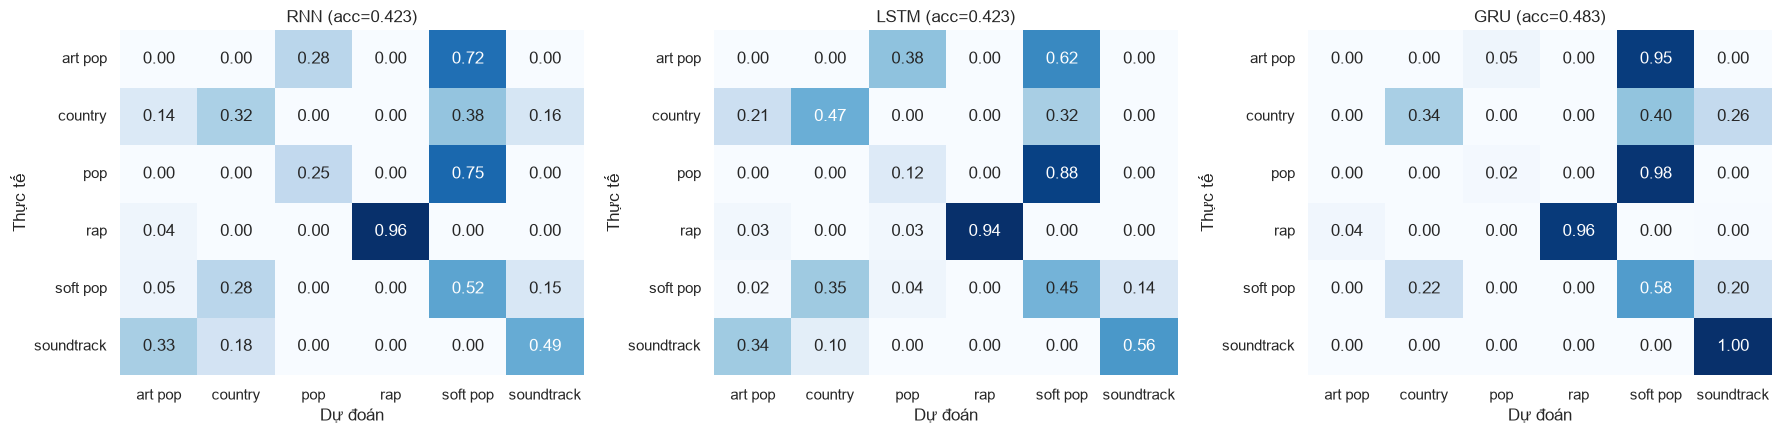

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, t in zip(axes, models):
    cm = confusion_matrix(y_true, preds[t], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"{t} (acc={results[t]:.3f})"); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
plt.tight_layout(); plt.show()

## 6. Nhận xét & báo cáo

### Kết quả (test, 6 thể loại, chance = 16.7%)

| Mô hình | Accuracy |
|---|---|
| GRU | 0.483 |
| SimpleRNN | 0.423 |
| LSTM | 0.423 |
| Logistic Regression (làm phẳng chuỗi) | 0.381 |
| Majority-class | 0.167 |

### Nhận xét
- **Mô hình có học được tín hiệu**: cả 3 mô hình recurrent đều vượt rõ rệt mức đoán ngẫu nhiên và vượt baseline logistic regression không có tính tuần tự. Với dữ liệu này, GRU nhỉnh hơn SimpleRNN/LSTM, nhưng chênh lệch (~6 điểm %) chỉ từ **một seed và một lần chia dữ liệu**, nên chưa đủ để kết luận GRU tốt hơn.
- **Tín hiệu chủ yếu đến từ mức trung bình của feature, không phải "xu hướng" theo thời gian.** `rap` được phân loại gần như hoàn hảo (F1 ≈ 0.98) vì tỷ lệ explicit rất khác biệt; `soundtrack` cũng dễ nhận ra nhờ thời lượng. `pop`, `soft pop`, `art pop` gần như không phân biệt được (`art pop` recall 0).
- **Overfit nặng**: accuracy train đạt ~98% trong khi val chỉ ~62% (test thấp hơn nữa, 42–48%), và val loss tăng gần như ngay từ epoch đầu nên early stopping chọn mô hình ở epoch rất sớm (xem biểu đồ). Mô hình ghi nhớ các nghệ sĩ trong train thay vì học quy luật chung. Nguyên nhân chính là số nguồn dữ liệu thật quá ít, không phải kiến trúc.
- Accuracy val (~62%) cao hơn test (42–48%) vì mỗi tập chỉ có ~30 nghệ sĩ, nên kết quả phụ thuộc nhiều vào nghệ sĩ nào rơi vào tập nào.

### Hạn chế
- Sau khi lọc (năm 2009–2025, có `artist_genres`, top 6 thể loại) chỉ còn ~1.500 dòng. Một số thể loại chỉ có rất ít nghệ sĩ (`pop` 8, `soft pop` 12, `art pop` 14). Vì chia theo nghệ sĩ nên tập train chỉ có 25 bài `art pop` còn test có 97.
- Hàng nghìn chuỗi được tạo bằng lấy mẫu con từ cùng một nhóm bài hát nên **không độc lập**; tập test chỉ có vài chục bài mỗi thể loại, nên con số accuracy có độ nhiễu lớn.
- Các thể loại chồng lấn nhau (một bài thuộc nhiều thể loại, vd `pop` và `soft pop`), nên nhãn không loại trừ nhau hoàn toàn.
- Chuỗi chỉ gồm 8 bước (cửa sổ theo năm), quá ngắn để RNN khai thác phụ thuộc dài hạn; ~51% bài không có thông tin thể loại bị loại.
- Chưa thử lại nhiều seed/siêu tham số, nên thứ hạng giữa các mô hình chỉ mang tính tham khảo.

### Hướng cải thiện
- Lặp nhiều seed và chia dữ liệu, báo cáo trung bình ± độ lệch chuẩn.
- Dùng dataset có audio feature thật (`energy`, `valence`, `danceability`) và nhiều nghệ sĩ hơn; tổng hợp theo tháng để chuỗi dài hơn.
- Chuyển sang bài toán hồi quy (dự đoán giá trị năm kế tiếp) như plan gợi ý.